# Import Library

In [38]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings("ignore")

## 2.Data understanding

In [8]:
wine_data = load_wine()
wine_data

{'data': array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
         1.065e+03],
        [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
         1.050e+03],
        [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
         1.185e+03],
        ...,
        [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
         8.350e+02],
        [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
         8.400e+02],
        [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
         5.600e+02]], shape=(178, 13)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [11]:
wine_data_pd = pd.DataFrame(wine_data.data,columns = wine_data.feature_names)
wine_data_pd["target"]=wine_data.target
wine_data_pd

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2


### 3. Data preparation

### 
1. Data cleaning
2. data transformation

#### Data cleaning

In [12]:
wine_data_pd.isna().sum()

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64

In [13]:
wine_data_pd.shape

(178, 14)

In [14]:
wine_data_pd.dtypes

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

In [15]:
wine_data_pd.duplicated().sum()

np.int64(0)

##### Data transformation we use here for standard scaler

In [27]:
X=wine_data_pd.drop(labels ="target",axis=1)
y=wine_data_pd["target"]

In [28]:
wine_data_pd

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2


In [29]:
std_scalar = StandardScaler()
scaled_X = std_scalar.fit_transform(X)
scaled_X



array([[ 1.51861254, -0.5622498 ,  0.23205254, ...,  0.36217728,
         1.84791957,  1.01300893],
       [ 0.24628963, -0.49941338, -0.82799632, ...,  0.40605066,
         1.1134493 ,  0.96524152],
       [ 0.19687903,  0.02123125,  1.10933436, ...,  0.31830389,
         0.78858745,  1.39514818],
       ...,
       [ 0.33275817,  1.74474449, -0.38935541, ..., -1.61212515,
        -1.48544548,  0.28057537],
       [ 0.20923168,  0.22769377,  0.01273209, ..., -1.56825176,
        -1.40069891,  0.29649784],
       [ 1.39508604,  1.58316512,  1.36520822, ..., -1.52437837,
        -1.42894777, -0.59516041]], shape=(178, 13))

### model buliding

In [34]:
 X_train, X_test, y_train, y_test = train_test_split(scaled_X,y,test_size =0.20,random_state = 1234,shuffle=True,stratify=y)
X_train.shape,y_train.shape
X_test.shape,y_test.shape

((36, 13), (36,))

In [ ]:
k=3

In [36]:
knn_classifier = KNeighborsClassifier(n_neighbors=3)
knn_classifier.fit(X_train,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


### model training

### train

In [41]:
y_predict_train = knn_classifier.predict(X_train)
print("Training Accuracy",round(accuracy_score(y_train,y_predict_train),4))

Training Accuracy 0.9789


### k=5

In [42]:
knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(X_train,y_train)
y_predict_train = knn_classifier.predict(X_train)
print("Training Accuracy",round(accuracy_score(y_train,y_predict_train),4))

Training Accuracy 0.9789


In [ ]:
# k=7

In [43]:
knn_classifier = KNeighborsClassifier(n_neighbors=7)
knn_classifier.fit(X_train,y_train)
y_predict_train = knn_classifier.predict(X_train)
print("Training Accuracy",round(accuracy_score(y_train,y_predict_train),4))

Training Accuracy 0.9718


### how to choose optimal no.of neightbour?

In [47]:
from sklearn.model_selection import KFold,cross_val_score

In [53]:
kfold= KFold(n_splits=5, shuffle=True, random_state=123)
cv_scores_mean  =[]
for i in range(3,52,2):
    knn_model = KNeighborsClassifier(n_neighbors=i)
    knn_model.fit(X_train,y_train)
    cv_scores=(cross_val_score(estimator=knn_model,X=X_train,y=y_train,cv=kfold))
    cv_scores_mean.append(cv_scores.mean().round(4))

In [54]:
cv_scores_mean

[np.float64(0.9367),
 np.float64(0.9579),
 np.float64(0.9441),
 np.float64(0.9579),
 np.float64(0.9581),
 np.float64(0.9581),
 np.float64(0.9579),
 np.float64(0.951),
 np.float64(0.951),
 np.float64(0.9441),
 np.float64(0.9438),
 np.float64(0.9438),
 np.float64(0.951),
 np.float64(0.9579),
 np.float64(0.9441),
 np.float64(0.951),
 np.float64(0.9581),
 np.float64(0.9581),
 np.float64(0.951),
 np.float64(0.951),
 np.float64(0.9438),
 np.float64(0.9367),
 np.float64(0.9367),
 np.float64(0.9367),
 np.float64(0.9438)]

In [55]:
max(cv_scores_mean)

np.float64(0.9581)

In [56]:
cv_scores_mean.index(max(cv_scores_mean))

4

### let visualize

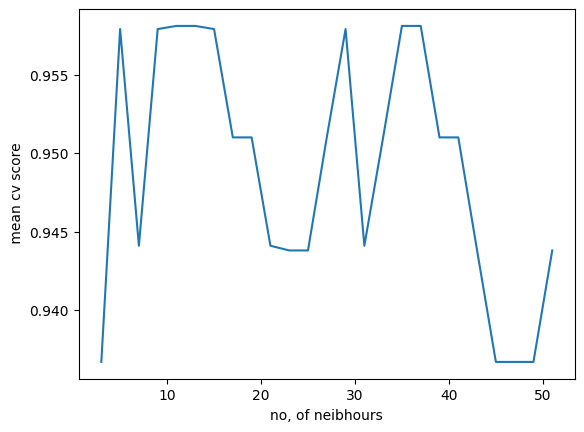

In [60]:
from matplotlib import pyplot as plt
plt.plot(range(3,52,2),cv_scores_mean)
plt.xlabel("no, of neibhours")
plt.ylabel(" mean cv score")
plt.show()

In [ ]:
1= 3
4=9 neibours

In [61]:
knn_classifier = KNeighborsClassifier(n_neighbors=9)
knn_classifier.fit(X_train,y_train)
y_predict_train = knn_classifier.predict(X_train)
print("Training Accuracy",round(accuracy_score(y_train,y_predict_train),4))

Training Accuracy 0.9718
